# Diversité du catalogue MDPForge

Décrire séparément les tâches, les tailles et les structures des modèles. Ces propriétés ne constituent pas un classement de difficulté des solveurs.

## 1. Périmètre et méthode

L'instantané fourni couvre **139 instances : 107 discounted et 32 total**, avec le preset `tiny` et une graine d'analyse (`SEED = 0`). Ses figures réutilisent les CSV de l'export du 18 novembre 2026 à 17:13 UTC, sans reconstruire les modèles ; une exécution complète du notebook actualise les données, les figures et leurs commentaires. Aucun solveur ni calcul de valeur optimale n'est lancé.

Chaque point représente une instance, avec le même poids ; les proportions internes donnent le même poids à chaque état ou couple état-action, sans supposer une fréquence de visite. Un successeur est un état de probabilité strictement positive ; une ligne déterministe conduit à un seul successeur avec probabilité 1, à `ATOL` près. Deux actions sont distinctes si leurs transitions ou leurs récompenses immédiates diffèrent exactement ; cela ne garantit pas des rendements différents. Les récompenses nulles et les différences de récompense entre actions sont comptées exactement.

Utiliser le noyau Conda `benchmark` et l'installation locale `mdpforge[notebooks]`. Les recettes et presets sont découverts automatiquement ; `MODEL_IDS`, `CATEGORIES` et `PRESETS` permettent de changer le périmètre. Les contrôles des matrices, les métriques détaillées et les exports sont conservés ; les diagnostics et l'illustration de `rooms` sont accessibles en annexe avec `SHOW_DIAGNOSTICS` et `SHOW_PREVIEW`.

In [1]:
import gc
import hashlib
import inspect
import json
import platform
import random
import subprocess
import warnings
from datetime import datetime, timezone
from importlib import import_module, metadata
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy.sparse.csgraph import connected_components

import mdpforge
from mdpforge.core.validation import validate_model
from mdpforge.models import discounted, total
from mdpforge.utils.persistence import model_cache_path

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file() and (path / "src/mdpforge").is_dir()
)
if not Path(mdpforge.__file__).resolve().is_relative_to(REPO_ROOT / "src"):
    raise RuntimeError("Installer mdpforge depuis ce checkout avant l'analyse.")

pd.set_option("display.max_colwidth", 100)
pd.set_option("display.max_rows", 30)
plt.rcParams.update(
    {
        "figure.figsize": (9, 5),
        "figure.dpi": 120,
        "font.size": 11,
        "axes.grid": True,
        "axes.axisbelow": True,
        "grid.alpha": 0.2,
        "axes.spines.top": False,
        "axes.spines.right": False,
    }
)
CRITERION_COLORS = {"discounted": "#0072B2", "total": "#D55E00"}
CRITERION_MARKERS = {"discounted": "o", "total": "^"}

In [2]:
CRITERIA = ("discounted", "total")
MODEL_IDS = None
CATEGORIES = None
PRESETS = ("tiny",)
ANALYZE_MATRICES = True
SEED = 0
CACHE_MODE = "readwrite"
ANALYZE_GRAPH = True
ATOL = 1e-12
PREVIEW_ID = "discounted:rooms"
PREVIEW_PRESET = "tiny"
PREVIEW_ACTION = 0
PREVIEW_STATES = 60
SHOW_DIAGNOSTICS = False
SHOW_PREVIEW = False
EXPORT = True
OUTPUT_ROOT = REPO_ROOT / "artifacts/tmp/model_diversity"

# Annotations relues : parenté de tâche, sans prétendre à l'équivalence des MDP.
# Une clé nue s'applique aux deux critères ; une clé qualifiée est prioritaire.
ANNOTATIONS = {
    "rooms": {
        "family": "four_rooms",
        "task": "Navigation vers une sortie dans quatre pièces",
        "evidence": "Description et référence Hengst dans les deux modules rooms.py.",
    },
    "maze_prims": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_prims.py : générateur de Prim.",
    },
    "maze_wilson": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_wilson.py : générateur de Wilson.",
    },
    "maze_backtrack": {
        "family": "generated_maze",
        "task": "Navigation dans un labyrinthe généré",
        "evidence": "Description du module maze_backtrack.py : génération par retour arrière.",
    },
    "discounted:consensus": {
        "family": "shared_coin_consensus",
        "origin": "PRISM",
        "task": "Coût de terminaison du consensus",
        "evidence": "Description et docstring du module consensus.py.",
    },
    "discounted:qvbs_consensus": {
        "family": "shared_coin_consensus",
        "origin": "qvbs",
        "task": "Coût de terminaison du consensus",
        "evidence": "Description et docstring du module qvbs_consensus.py.",
    },
    "discounted:jani_rabin": {
        "family": "rabin_mutual_exclusion",
        "origin": "jani-models",
        "evidence": "Description Rabin mutual exclusion et source_collection du module.",
    },
    "discounted:prism_rabin": {
        "family": "rabin_mutual_exclusion",
        "origin": "PRISM",
        "evidence": "Description et docstring du module prism_rabin.py.",
    },
}

# Renseigner family, origin, task, objective, temporal_type, evidence si connus.
# Une valeur absente reste inconnue, même si un nom suggère une parenté.
CATALOGUES = {"discounted": discounted, "total": total}
if not CRITERIA or set(CRITERIA) - CATALOGUES.keys():
    raise ValueError("CRITERIA doit contenir discounted et/ou total.")
if not PRESETS or len(set(PRESETS)) != len(PRESETS):
    raise ValueError("PRESETS doit être une séquence non vide sans doublons.")

In [3]:
catalogue_rows = []
preset_rows = []
entries_by_id = {}
for criterion in CRITERIA:
    for entry in CATALOGUES[criterion].list_models():
        model_id = f"{criterion}:{entry['name']}"
        entries_by_id[model_id] = entry
        annotation = ANNOTATIONS.get(model_id, ANNOTATIONS.get(entry["name"], {}))
        row = {
            "model_id": model_id,
            "criterion": criterion,
            "recipe": entry["name"],
            "category": entry.get("category"),
            "available": entry.get("available", True),
            "unavailable_reason": entry.get("reason"),
            "family": annotation.get("family"),
            "task": annotation.get("task"),
            "objective": annotation.get("objective"),
            "temporal_type": annotation.get("temporal_type"),
            "origin": annotation.get("origin", entry.get("source_collection")),
            "annotation_evidence": annotation.get("evidence"),
            "source_url": entry.get("source_url"),
        }
        row["family_reviewed"] = bool(row["family"] and row["annotation_evidence"])
        if row["family"] and not row["family_reviewed"]:
            raise ValueError(
                f"Une famille annotée doit avoir une justification : {model_id}"
            )
        row["selected"] = (MODEL_IDS is None or model_id in MODEL_IDS) and (
            CATEGORIES is None or row["category"] in CATEGORIES
        )
        catalogue_rows.append(row)
        for preset, options in entry.get("sizes", {}).items():
            preset_rows.append(
                {
                    "model_id": model_id,
                    "preset": preset,
                    "requested_states": options.get("requested_state_dim"),
                    "parameters": options.get("parameters"),
                    "preset_available": options.get("parameters") is not None,
                    "preset_reason": options.get("reason"),
                }
            )

catalogue = pd.DataFrame(catalogue_rows)
presets = pd.DataFrame(preset_rows)
if MODEL_IDS is not None and set(MODEL_IDS) - set(catalogue.model_id):
    raise ValueError(
        f"Identifiants inconnus : {set(MODEL_IDS) - set(catalogue.model_id)}"
    )
if CATEGORIES is not None and set(CATEGORIES) - set(catalogue.category):
    raise ValueError(
        f"Catégories inconnues : {set(CATEGORIES) - set(catalogue.category)}"
    )
if set(PRESETS) - set(presets.preset):
    raise ValueError(f"Presets inconnus : {set(PRESETS) - set(presets.preset)}")
selected = catalogue.loc[catalogue.selected].copy()
if selected.empty:
    raise ValueError("La sélection est vide.")

In [4]:
def transition_metrics(transitions):
    """Décrire les probabilités et les supports sans changer les matrices."""
    states = transitions[0].shape[0]
    absorbing = np.ones(states, dtype=bool)
    degrees = []
    action_rows = []
    for action, matrix in enumerate(transitions):
        degree = np.diff(matrix.indptr)
        diagonal = matrix.diagonal()
        row_sum = np.asarray(matrix.sum(axis=1)).ravel()
        deterministic = (degree == 1) & np.isclose(row_sum, 1, atol=ATOL, rtol=0)
        absorbing &= (degree == 1) & np.isclose(diagonal, 1, atol=ATOL, rtol=0)
        entropy = -np.sum(matrix.data * np.log2(matrix.data)) / states
        action_rows.append(
            {
                "action": action,
                "transition_nnz": matrix.nnz,
                "transition_density": matrix.nnz / states**2,
                "successors_min": degree.min(),
                "successors_median": np.median(degree),
                "successors_p90": np.quantile(degree, 0.9),
                "successors_max": degree.max(),
                "successors_mean": degree.mean(),
                "deterministic_share": deterministic.mean(),
                "self_loop_mass_mean": diagonal.mean(),
                "entropy_bits_mean": entropy,
                "row_sum_error_max": np.max(np.abs(row_sum - 1)),
            }
        )
        degrees.append(degree)
    degrees = np.concatenate(degrees)
    actions = len(transitions)
    table = pd.DataFrame(action_rows)
    result = {
        "transition_nnz": int(table.transition_nnz.sum()),
        "transition_density": table.transition_nnz.sum() / (actions * states**2),
        "successors_min": int(degrees.min()),
        "successors_median": np.median(degrees),
        "successors_p90": np.quantile(degrees, 0.9),
        "successors_max": int(degrees.max()),
        "successors_mean": degrees.mean(),
        "deterministic_share": table.deterministic_share.mean(),
        "self_loop_mass_mean": table.self_loop_mass_mean.mean(),
        "entropy_bits_mean": table.entropy_bits_mean.mean(),
        "absorbing_states": int(absorbing.sum()),
        "absorbing_share": absorbing.mean(),
        "row_sum_error_max": table.row_sum_error_max.max(),
    }
    return result, action_rows


def reward_metrics(rewards):
    """Décrire les valeurs de récompense et leur variation entre actions."""
    return {
        "reward_min": rewards.min(),
        "reward_p10": np.quantile(rewards, 0.1),
        "reward_median": np.median(rewards),
        "reward_p90": np.quantile(rewards, 0.9),
        "reward_max": rewards.max(),
        "reward_mean": rewards.mean(),
        "reward_std": rewards.std(),
        "reward_range": np.ptp(rewards),
        "reward_zero_share": np.mean(rewards == 0),
        "reward_positive_share": np.mean(rewards > 0),
        "reward_negative_share": np.mean(rewards < 0),
        "reward_constant": bool(np.all(rewards == rewards.flat[0])),
        "reward_action_varying_state_share": np.mean(np.ptp(rewards, axis=1) != 0),
    }


def action_metrics(transitions, rewards):
    """Compter les actions distinctes par état par comparaison exacte."""
    actions = len(transitions)
    counts = np.ones(rewards.shape[0], dtype=int)
    for action in range(1, actions):
        repeated = np.zeros(rewards.shape[0], dtype=bool)
        for previous in range(action):
            difference = transitions[action] - transitions[previous]
            difference.eliminate_zeros()
            repeated |= (np.diff(difference.indptr) == 0) & (
                rewards[:, action] == rewards[:, previous]
            )
        counts += ~repeated
    return {
        "action_comparison_status": "computed",
        "distinct_actions_mean": counts.mean(),
        "distinct_action_share": counts.mean() / actions,
        "single_choice_state_share": np.mean(counts == 1),
    }

In [5]:
def graph_metrics(transitions):
    """Décrire le graphe réunissant les supports de toutes les actions."""
    if not ANALYZE_GRAPH:
        return {"graph_status": "disabled"}
    graph = transitions[0].astype(bool)
    for matrix in transitions[1:]:
        graph = graph.maximum(matrix.astype(bool))
    count, labels = connected_components(graph, directed=True, connection="strong")
    sizes = np.bincount(labels, minlength=count)
    edges = graph.tocoo()
    crossing = labels[edges.row] != labels[edges.col]
    outgoing_components = np.unique(labels[edges.row[crossing]])
    return {
        "graph_status": "computed",
        "scc_count": count,
        "largest_scc_share": sizes.max() / graph.shape[0],
        "sink_scc_count": count - len(outgoing_components),
        "nontrivial_cycle_state_share": np.mean(sizes[labels] > 1),
    }


def matrix_fingerprint(transitions, rewards):
    """Identifier les matrices canoniques dans leur ordre actuel."""
    digest = hashlib.sha256()
    for matrix in transitions:
        digest.update(np.asarray(matrix.shape, dtype="<i8").tobytes())
        for values, dtype in (
            (matrix.indptr, "<i8"),
            (matrix.indices, "<i8"),
            (matrix.data, "<f8"),
        ):
            digest.update(np.asarray(values, dtype=dtype).tobytes())
    digest.update(np.asarray(rewards.shape, dtype="<i8").tobytes())
    digest.update(np.asarray(rewards, dtype="<f8").tobytes())
    return digest.hexdigest()


def declared_count(model, plural, singular):
    """Compter une déclaration disponible sans inférer sa signification."""
    if hasattr(model, plural):
        values = getattr(model, plural)
        return len(values) if values is not None else np.nan
    if hasattr(model, singular):
        return 1 if getattr(model, singular) is not None else np.nan
    return np.nan

In [6]:
plan = (
    selected[["model_id", "criterion", "recipe", "category", "available"]]
    .merge(pd.DataFrame({"preset": PRESETS}), how="cross")
    .merge(presets, how="left", on=["model_id", "preset"])
)

In [7]:
def analyze_instance(item):
    """Construire une instance puis en extraire seulement des descriptions."""
    row = dict(item)
    row.update(status="pending", reason=None, stage="selection", warnings=None)
    if not row["available"]:
        row.update(
            status="unavailable", reason=entries_by_id[row["model_id"]].get("reason")
        )
        return row, [], None
    if pd.isna(row["preset_available"]) or not row["preset_available"]:
        reason = (
            row["preset_reason"] if pd.notna(row["preset_reason"]) else "Preset absent."
        )
        row.update(status="unavailable_preset", reason=reason)
        return row, [], None
    if not ANALYZE_MATRICES:
        row.update(status="disabled", reason="Inventaire seul.")
        return row, [], None
    numpy_state, python_state = np.random.get_state(), random.getstate()
    model = None
    action_rows = []
    preview_data = None
    start = perf_counter()
    caught = []
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            np.random.seed(SEED)
            random.seed(SEED)
            row["stage"] = "construction"
            constructor = import_module(
                f"mdpforge.models.{row['criterion']}.{row['recipe']}"
            ).Model
            options = dict(row["parameters"])
            options["state_dim"] = int(row["requested_states"])
            # Désactiver aussi la limite native des lecteurs qui l'exposent.
            if "state_limit" in inspect.signature(constructor).parameters:
                options["state_limit"] = None
            row["constructor_options"] = options
            model = constructor(**options)
            row.update(
                model_name=model.name, states=model.state_dim, actions=model.action_dim
            )
            expected_shape = (model.state_dim, model.action_dim)
            row["cache_present_before"] = model_cache_path(model).exists()
            model.create_model(cache=CACHE_MODE)
            row["build_seconds"] = perf_counter() - start
            if (model.state_dim, model.action_dim) != expected_shape:
                raise ValueError(
                    "Les dimensions après create_model diffèrent du constructeur."
                )
            row["model_config"] = model.get_config()
            row["declared_terminal_states"] = declared_count(
                model, "terminal_states", "terminal_state"
            )
            row["declared_initial_states"] = declared_count(
                model, "initial_states", "initial_state"
            )
            row["state_action_pairs"] = model.state_dim * model.action_dim
            row["state_target_ratio"] = model.state_dim / row["requested_states"]
            row["stage"] = "matrix_validation"
            validate_model(model)
            row["matrix_validation"] = "passed"
            row["stage"] = "description"
            transitions = []
            for matrix in model.transition_matrix:
                matrix = matrix.copy()
                matrix.sum_duplicates()
                matrix.eliminate_zeros()
                matrix.sort_indices()
                transitions.append(matrix)
            rewards = model.reward_matrix
            metrics, action_rows = transition_metrics(transitions)
            row.update(metrics)
            row.update(reward_metrics(rewards))
            row.update(action_metrics(transitions, rewards))
            row.update(graph_metrics(transitions))
            row["matrix_sha256"] = matrix_fingerprint(transitions, rewards)
            row["matrix_storage_mib"] = (
                sum(
                    m.data.nbytes + m.indices.nbytes + m.indptr.nbytes
                    for m in model.transition_matrix
                )
                + rewards.nbytes
            ) / 2**20
            for action_row in action_rows:
                action = action_row["action"]
                action_row.update(
                    model_id=row["model_id"],
                    preset=row["preset"],
                    reward_min=rewards[:, action].min(),
                    reward_max=rewards[:, action].max(),
                    reward_zero_share=np.mean(rewards[:, action] == 0),
                )
            if (row["model_id"], row["preset"]) == (PREVIEW_ID, PREVIEW_PRESET):
                if not 0 <= PREVIEW_ACTION < model.action_dim:
                    raise ValueError(
                        "PREVIEW_ACTION n'est pas une action de cette instance."
                    )
                stop = min(PREVIEW_STATES, model.state_dim)
                preview_data = {
                    "transition": transitions[PREVIEW_ACTION][:stop, :stop].toarray(),
                    "reward": rewards[:stop, :].copy(),
                    "successors": np.concatenate(
                        [np.diff(m.indptr) for m in transitions]
                    ),
                    "reward_values": rewards.ravel().copy(),
                    "states": model.state_dim,
                    "actions": model.action_dim,
                }
            row.update(status="analyzed", stage="complete")
    except ModuleNotFoundError as exc:
        row.update(status="missing_dependency", reason=f"{type(exc).__name__}: {exc}")
    except Exception as exc:
        row.update(status="error", reason=f"{type(exc).__name__}: {exc}")
        action_rows, preview_data = [], None
    finally:
        row["warnings"] = [str(item.message) for item in caught]
        row["elapsed_seconds"] = perf_counter() - start
        np.random.set_state(numpy_state)
        random.setstate(python_state)
        del model
        gc.collect()
    return row, action_rows, preview_data


instance_rows, per_action_rows, preview = [], [], None
for index, item in enumerate(plan.to_dict("records"), start=1):
    row, action_rows, image_data = analyze_instance(item)
    instance_rows.append(row)
    per_action_rows.extend(action_rows)
    if image_data is not None:
        preview = image_data
    if row["status"] != "analyzed":
        print(
            f"{item['model_id']} [{item['preset']}]: {row['status']} — {row['reason']}"
        )

instances = pd.DataFrame(instance_rows)
per_action = pd.DataFrame(per_action_rows)
metrics = instances.loc[instances.status.eq("analyzed")].copy()

In [8]:
criterion_counts = metrics.groupby("criterion").size()
scope_counts = ", ".join(
    f"{int(criterion_counts.get(criterion, 0))} {criterion}" for criterion in CRITERIA
)
display(
    Markdown(
        f"**Périmètre calculé :** {len(catalogue)} recettes au catalogue, "
        f"{len(selected)} sélectionnées ; **{len(metrics)}/{len(instances)} instances analysées** "
        f"({scope_counts}), presets : {', '.join(PRESETS)}, graine : {SEED}. "
        "Les figures de structure portent uniquement sur les instances analysées ; "
        "les échecs éventuels restent dans `instances.csv`."
    )
)

**Périmètre calculé :** 139 recettes au catalogue, 139 sélectionnées ; **139/139 instances analysées** (107 discounted, 32 total), presets : tiny, graine : 0. Les figures de structure portent uniquement sur les instances analysées ; les échecs éventuels restent dans `instances.csv`.

## 2. Diversité des tâches

Les catégories décrivent les domaines déclarés dans le catalogue. Les barres comptent les recettes sélectionnées, séparées par critère ; le critère moyen réutilise le catalogue discounted.

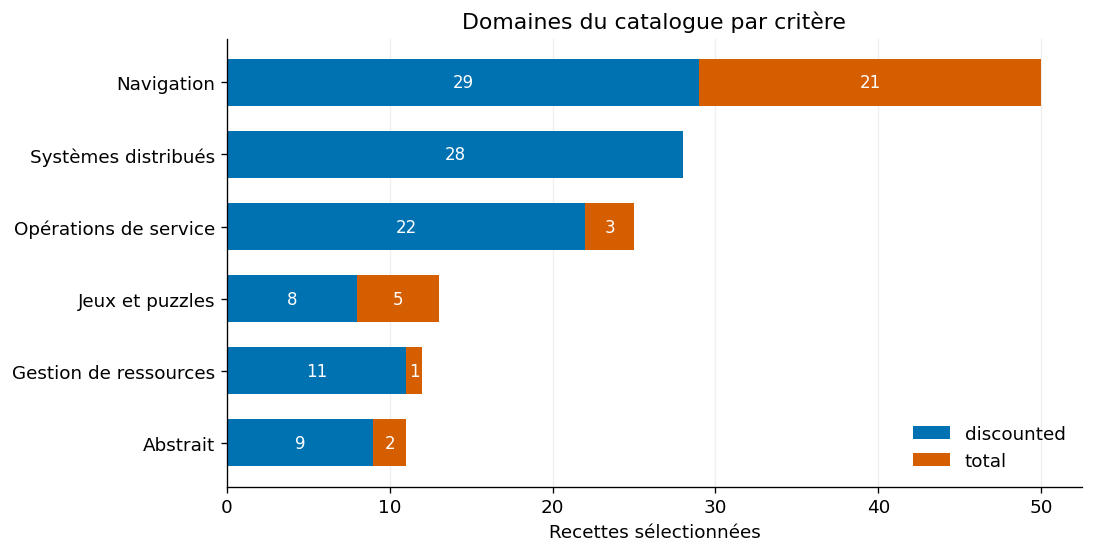

In [9]:
task_counts = pd.crosstab(selected.category, selected.criterion).reindex(
    columns=CRITERION_COLORS, fill_value=0
)
task_counts = task_counts.loc[task_counts.sum(axis=1).sort_values().index]
category_labels = {
    "abstract": "Abstrait",
    "asset_management": "Gestion de ressources",
    "distributed_systems": "Systèmes distribués",
    "games_and_puzzles": "Jeux et puzzles",
    "navigation": "Navigation",
    "service_operations": "Opérations de service",
}
fig, ax = plt.subplots(figsize=(9, 4.5), layout="constrained")
left = np.zeros(len(task_counts))
for criterion, color in CRITERION_COLORS.items():
    bars = ax.barh(
        np.arange(len(task_counts)),
        task_counts[criterion],
        left=left,
        color=color,
        label=criterion,
        height=0.65,
    )
    ax.bar_label(
        bars,
        labels=[str(value) if value else "" for value in task_counts[criterion]],
        label_type="center",
        color="white",
        fontsize=10,
    )
    left += task_counts[criterion].to_numpy()
ax.set_yticks(
    np.arange(len(task_counts)),
    [category_labels.get(category, category) for category in task_counts.index],
)
ax.set(xlabel="Recettes sélectionnées", title="Domaines du catalogue par critère")
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True, steps=[1, 2, 5, 10]))
ax.grid(axis="y", visible=False)
ax.legend(loc="lower right", frameon=False)
plt.show()

In [10]:
domain_counts = selected.groupby("category").size().sort_values(ascending=False)
dominant_category = domain_counts.index[0]
reviewed_count = int(selected.family_reviewed.sum())
display(
    Markdown(
        f"**Lecture.** Le domaine le plus représenté est « {category_labels.get(dominant_category, dominant_category)} » "
        f"avec {domain_counts.iloc[0]}/{len(selected)} recettes ; les domaines ont donc des poids inégaux. "
        f"Les familles documentées ne couvrent que **{reviewed_count}/{len(selected)} recettes** "
        f"({selected.family.nunique()} familles annotées) : "
        "ces effectifs ne mesurent pas le nombre de tâches indépendantes."
    )
)

**Lecture.** Le domaine le plus représenté est « Navigation » avec 50/139 recettes ; les domaines ont donc des poids inégaux. Les familles documentées ne couvrent que **12/139 recettes** (4 familles annotées) : ces effectifs ne mesurent pas le nombre de tâches indépendantes.

## 3. Tailles et transitions

Les dimensions sont celles des modèles construits, pas les tailles demandées au constructeur. Les deux panneaux utilisent des échelles logarithmiques ; le branchement est le nombre moyen de successeurs par couple état-action.

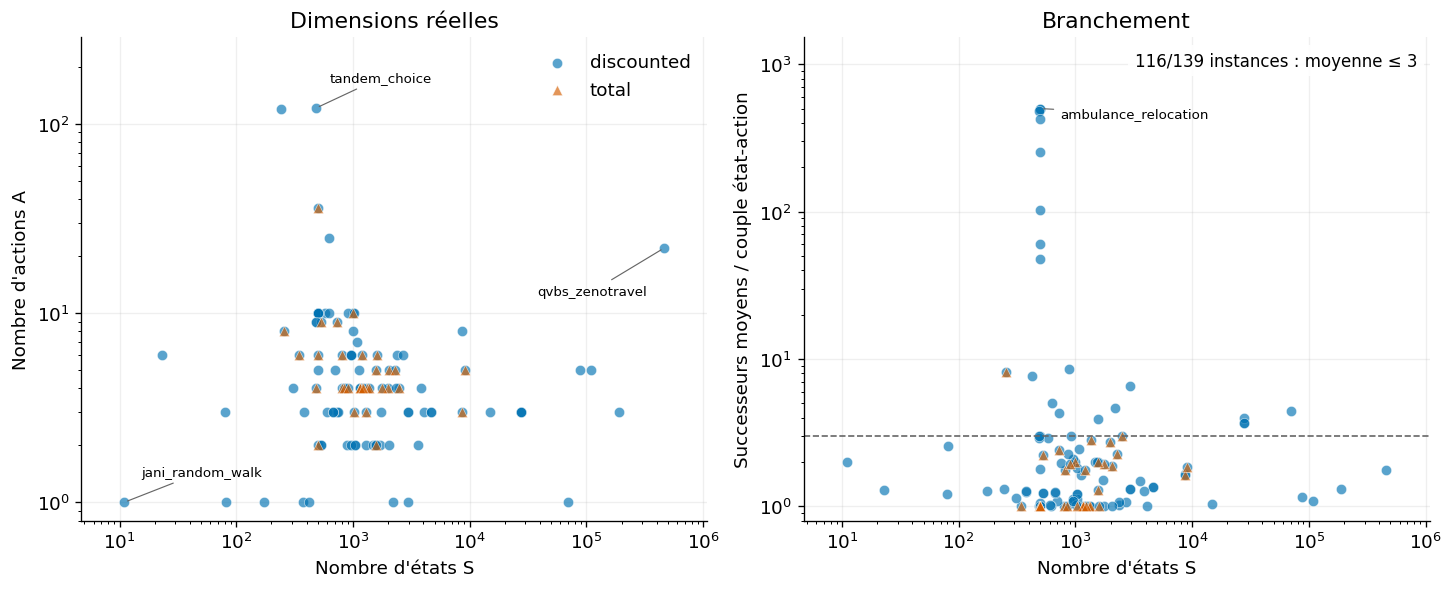

In [11]:
if not metrics.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
    for criterion, color in CRITERION_COLORS.items():
        group = metrics.loc[metrics.criterion.eq(criterion)]
        for ax, column in zip(axes, ("actions", "successors_mean")):
            ax.scatter(
                group.states,
                group[column],
                color=color,
                marker=CRITERION_MARKERS[criterion],
                label=criterion,
                s=38,
                alpha=0.65,
                edgecolors="white",
                linewidths=0.4,
            )
    for ax in axes:
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlabel("Nombre d'états S")
        ax.margins(x=0.08, y=0.18)
        ax.set_ylim(bottom=0.8)
    axes[0].set(ylabel="Nombre d'actions A", title="Dimensions réelles")
    axes[1].set(ylabel="Successeurs moyens / couple état-action", title="Branchement")
    size_extremes = [
        (metrics.states.idxmin(), (10, 16)),
        (metrics.states.idxmax(), (-10, -28)),
        (metrics.actions.idxmax(), (8, 16)),
    ]
    for index, offset in size_extremes:
        row = metrics.loc[index]
        axes[0].annotate(
            row.recipe,
            (row.states, row.actions),
            xytext=offset,
            textcoords="offset points",
            fontsize=8,
            ha="right" if offset[0] < 0 else "left",
            arrowprops={"arrowstyle": "-", "color": "0.4", "lw": 0.7},
        )
    branching_extreme = metrics.loc[metrics.successors_mean.idxmax()]
    axes[1].annotate(
        branching_extreme.recipe,
        (branching_extreme.states, branching_extreme.successors_mean),
        xytext=(12, -5),
        textcoords="offset points",
        fontsize=8,
        arrowprops={"arrowstyle": "-", "color": "0.4", "lw": 0.7},
    )
    low_branch_count = int(metrics.successors_mean.le(3).sum())
    axes[1].axhline(3, color="0.4", linestyle="--", linewidth=1)
    axes[1].text(
        0.98,
        0.97,
        f"{low_branch_count}/{len(metrics)} instances : moyenne ≤ 3",
        transform=axes[1].transAxes,
        ha="right",
        va="top",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
    axes[0].legend(loc="upper right", frameon=False)
    plt.show()

In [12]:
if not metrics.empty:
    display(
        Markdown(
            f"**Lecture.** Les instances analysées vont de **{int(metrics.states.min())} à "
            f"{int(metrics.states.max())} états**, et de {int(metrics.actions.min())} à "
            f"{int(metrics.actions.max())} actions : un même nom de preset ne garantit pas une taille comparable. "
            f"Le branchement reste faible pour **{low_branch_count}/{len(metrics)} instances** "
            "(au plus trois successeurs en moyenne), malgré quelques modèles à branchement élevé. "
            "Ces dimensions décrivent les matrices ; elles ne suffisent pas à prédire le temps de résolution."
        )
    )

**Lecture.** Les instances analysées vont de **11 à 462400 états**, et de 1 à 121 actions : un même nom de preset ne garantit pas une taille comparable. Le branchement reste faible pour **116/139 instances** (au plus trois successeurs en moyenne), malgré quelques modèles à branchement élevé. Ces dimensions décrivent les matrices ; elles ne suffisent pas à prédire le temps de résolution.

## 4. Structure des décisions

La part de lignes déterministes décrit l'aléa des transitions. La part d'états sans choix distinct vaut la proportion d'états où toutes les actions ont exactement les mêmes transitions et récompenses immédiates ; ces deux propriétés mesurent des aspects différents.

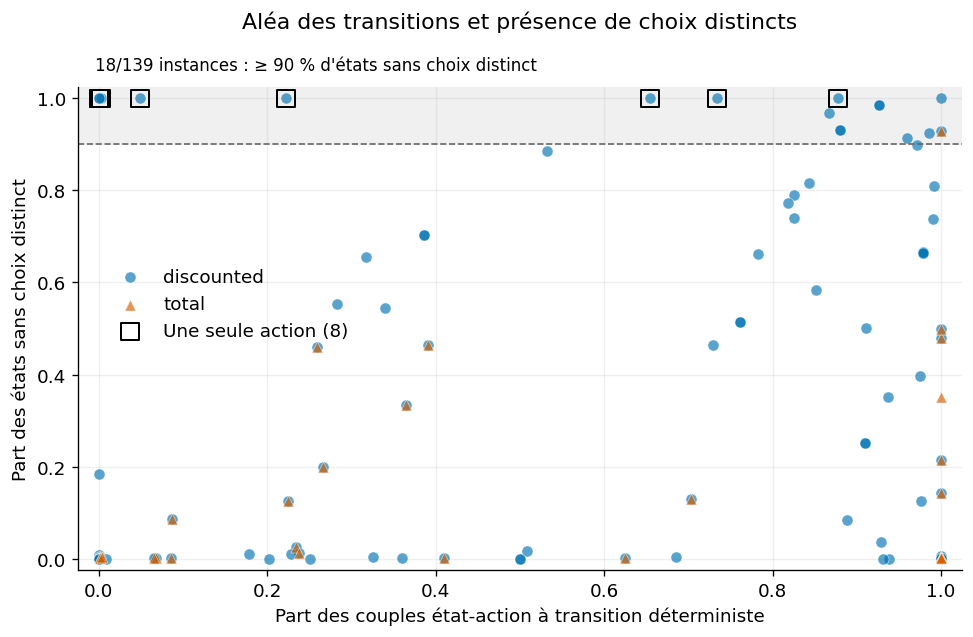

In [13]:
if not metrics.empty:
    single_action = metrics.actions.eq(1)
    mostly_no_choice = metrics.single_choice_state_share.ge(0.9)
    fig, ax = plt.subplots(figsize=(8, 5.2), layout="constrained")
    ax.axhspan(0.9, 1.025, color="0.94", zorder=0)
    ax.axhline(0.9, color="0.4", linestyle="--", linewidth=1)
    for criterion, color in CRITERION_COLORS.items():
        group = metrics.loc[metrics.criterion.eq(criterion)]
        ax.scatter(
            group.deterministic_share,
            group.single_choice_state_share,
            color=color,
            marker=CRITERION_MARKERS[criterion],
            label=criterion,
            s=44,
            alpha=0.65,
            edgecolors="white",
            linewidths=0.4,
        )
    group = metrics.loc[single_action]
    ax.scatter(
        group.deterministic_share,
        group.single_choice_state_share,
        facecolors="none",
        edgecolors="black",
        marker="s",
        s=110,
        linewidths=1.2,
        label=f"Une seule action ({int(single_action.sum())})",
    )
    ax.text(
        0.02,
        1.025,
        f"{int(mostly_no_choice.sum())}/{len(metrics)} instances : ≥ 90 % d'états sans choix distinct",
        transform=ax.transAxes,
        va="bottom",
        fontsize=10,
        bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
    )
    ax.set(
        xlabel="Part des couples état-action à transition déterministe",
        ylabel="Part des états sans choix distinct",
        xlim=(-0.025, 1.025),
        ylim=(-0.025, 1.025),
    )
    ax.set_title("Aléa des transitions et présence de choix distincts", pad=35)
    ax.legend(loc="center left", bbox_to_anchor=(0.02, 0.55), frameon=False)
    plt.show()

In [14]:
if not metrics.empty:
    display(
        Markdown(
            f"**Lecture.** **{int(single_action.sum())} instances n'ont qu'une action**, "
            f"et **{int(mostly_no_choice.sum())} ont au moins 90 % d'états sans choix distinct** "
            "(le premier groupe est inclus dans le second). "
            "Des transitions stochastiques peuvent donc coexister avec très peu de choix, "
            "tandis qu'un modèle déterministe peut proposer plusieurs actions distinctes. "
            "Cette comparaison porte sur tous les états représentés, sans établir leur accessibilité ni l'effet des choix sur le rendement."
        )
    )

**Lecture.** **8 instances n'ont qu'une action**, et **18 ont au moins 90 % d'états sans choix distinct** (le premier groupe est inclus dans le second). Des transitions stochastiques peuvent donc coexister avec très peu de choix, tandis qu'un modèle déterministe peut proposer plusieurs actions distinctes. Cette comparaison porte sur tous les états représentés, sans établir leur accessibilité ni l'effet des choix sur le rendement.

## 5. Structure des récompenses

L'axe horizontal compte les couples état-action de récompense immédiate nulle. L'axe vertical compte les états où cette récompense varie entre actions ; aucune comparaison d'écarts-types entre unités natives n'est utilisée.

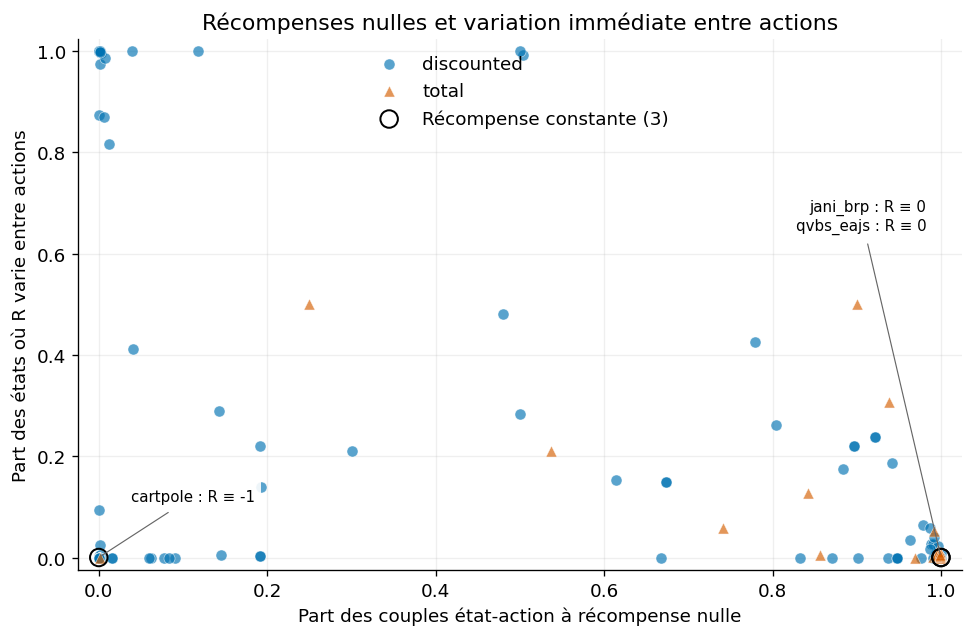

In [15]:
if not metrics.empty:
    fig, ax = plt.subplots(figsize=(8, 5.2), layout="constrained")
    for criterion, color in CRITERION_COLORS.items():
        group = metrics.loc[metrics.criterion.eq(criterion)]
        ax.scatter(
            group.reward_zero_share,
            group.reward_action_varying_state_share,
            color=color,
            marker=CRITERION_MARKERS[criterion],
            label=criterion,
            s=44,
            alpha=0.65,
            edgecolors="white",
            linewidths=0.4,
        )
    constant_rewards = metrics.loc[metrics.reward_constant]
    ax.scatter(
        constant_rewards.reward_zero_share,
        constant_rewards.reward_action_varying_state_share,
        facecolors="none",
        edgecolors="black",
        s=110,
        linewidths=1.2,
        label=f"Récompense constante ({len(constant_rewards)})",
    )
    for (zero_share, varying_share), group in constant_rewards.groupby(
        ["reward_zero_share", "reward_action_varying_state_share"]
    ):
        label = "\n".join(
            f"{row.recipe} : R ≡ {row.reward_min:g}" for row in group.itertuples()
        )
        ax.annotate(
            label,
            (zero_share, varying_share),
            xytext=(0.96, 0.64) if zero_share > 0.5 else (0.06, 0.13),
            textcoords="axes fraction",
            fontsize=9,
            ha="right" if zero_share > 0.5 else "left",
            arrowprops={"arrowstyle": "-", "color": "0.4", "lw": 0.7},
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.9},
        )
    ax.set(
        xlabel="Part des couples état-action à récompense nulle",
        ylabel="Part des états où R varie entre actions",
        xlim=(-0.025, 1.025),
        ylim=(-0.025, 1.025),
        title="Récompenses nulles et variation immédiate entre actions",
    )
    ax.legend(loc="upper center", frameon=False)
    plt.show()

In [16]:
if not metrics.empty:
    constant_names = (
        ", ".join(
            f"`{row.model_id}` (R ≡ {row.reward_min:g})"
            for row in constant_rewards.itertuples()
        )
        or "aucune"
    )
    display(
        Markdown(
            f"**Lecture.** Les **{len(constant_rewards)} instances à récompense constante** "
            f"sont : {constant_names}. "
            "Pour un modèle discounted dont la récompense immédiate est constante partout, "
            "le rendement est indépendant de la politique ; ces cas doivent être distingués des problèmes où l'objectif permet de départager les politiques. "
            "Une récompense identique entre actions dans un état ne suffit toutefois pas à supprimer la décision, car les transitions et les récompenses futures peuvent différer."
        )
    )

**Lecture.** Les **3 instances à récompense constante** sont : `discounted:cartpole` (R ≡ -1), `discounted:jani_brp` (R ≡ 0), `discounted:qvbs_eajs` (R ≡ 0). Pour un modèle discounted dont la récompense immédiate est constante partout, le rendement est indépendant de la politique ; ces cas doivent être distingués des problèmes où l'objectif permet de départager les politiques. Une récompense identique entre actions dans un état ne suffit toutefois pas à supprimer la décision, car les transitions et les récompenses futures peuvent différer.

## 6. Conclusions et limites

In [17]:
if not metrics.empty:
    duplicates = metrics.loc[
        metrics.duplicated("matrix_sha256", keep=False)
    ].sort_values("matrix_sha256")
    duplicate_groups = [
        " = ".join(f"`{row.model_id}` [{row.preset}]" for row in group.itertuples())
        for _, group in duplicates.groupby("matrix_sha256")
    ]
    duplicate_text = "; ".join(duplicate_groups) or "aucun doublon exact observé"
    display(
        Markdown(
            f"**Tâches.** Les {len(selected)} recettes sélectionnées couvrent "
            f"{selected.category.nunique()} domaines déclarés, mais les familles documentées "
            f"ne couvrent que {reviewed_count} recettes ; le nombre de problèmes indépendants reste inconnu.\n\n"
            f"**Tailles.** L'étendue des dimensions réelles confirme que les presets ne constituent pas "
            f"des classes de taille homogènes entre recettes.\n\n"
            f"**Structures.** Le catalogue combine plusieurs degrés d'aléa et de choix, "
            f"avec {low_branch_count}/{len(metrics)} instances à branchement moyen ≤ 3, "
            f"{int(mostly_no_choice.sum())} instances à au moins 90 % d'états sans choix distinct, "
            f"et {len(constant_rewards)} récompenses constantes.\n\n"
            f"**Matrices identiques.** {duplicate_text}. "
            "Les empreintes comparent les matrices canoniques dans le même ordre d'états et d'actions ; "
            "elles ne détectent pas les équivalences après permutation."
        )
    )
else:
    display(
        Markdown(
            "Aucune instance analysée : seule la couverture des tâches est décrite."
        )
    )

**Tâches.** Les 139 recettes sélectionnées couvrent 6 domaines déclarés, mais les familles documentées ne couvrent que 12 recettes ; le nombre de problèmes indépendants reste inconnu.

**Tailles.** L'étendue des dimensions réelles confirme que les presets ne constituent pas des classes de taille homogènes entre recettes.

**Structures.** Le catalogue combine plusieurs degrés d'aléa et de choix, avec 116/139 instances à branchement moyen ≤ 3, 18 instances à au moins 90 % d'états sans choix distinct, et 3 récompenses constantes.

**Matrices identiques.** `discounted:jani_beb_modest` [tiny] = `discounted:qvbs_beb` [tiny]. Les empreintes comparent les matrices canoniques dans le même ordre d'états et d'actions ; elles ne détectent pas les équivalences après permutation.

Ces observations décrivent les instances construites pour les presets et graines affichés. D'autres presets et plusieurs graines sont nécessaires pour étudier l'évolution des structures avec la taille et la variabilité des générateurs ; la graine d'analyse ne remplace pas les graines internes des recettes. Des familles mieux documentées sont nécessaires pour évaluer la diversité des tâches indépendamment des variantes de critère et de source.

Aucune difficulté de résolution n'est déduite des figures : elle demanderait des benchmarks de solveurs avec précision, discount et protocole de mesure explicites. Les statistiques portent sur tous les états, y compris ceux qui pourraient être inaccessibles ; les contrôles des matrices ne certifient ni une solution, ni l'absorption sous toute politique, ni la finitude du rendement total.

### Annexe technique — diagnostics et reproductibilité

Les calculs conservent les copies CSR canoniques, les validations de dimensions et de probabilités, les récompenses dans leurs unités natives, les comparaisons exactes d'actions et les statistiques du graphe réunissant toutes les actions. Les composantes fortement connexes (SCC) décrivent des groupes d'états mutuellement accessibles dans ce graphe, sans certifier une propriété sous toute politique ; un état absorbant n'est pas nécessairement une fin de tâche.

La construction conserve le cache `readwrite`, sans purge ni calcul de référence, restaure les générateurs globaux NumPy et Python et ne fixe aucun plafond de taille. Les temps de construction et de description ne mesurent pas un temps de résolution ; la présence préalable d'un cache ne prouve pas son utilisation. `SHOW_DIAGNOSTICS = True` affiche un bilan technique compact ; les lignes complètes restent dans les CSV.

In [18]:
if not metrics.empty:
    metrics["dynamics_class"] = np.select(
        [metrics.deterministic_share == 1, metrics.deterministic_share == 0],
        ["déterministe", "stochastique partout"],
        default="mixte",
    )
    metrics["absorption_class"] = np.where(
        metrics.absorbing_states > 0, "avec état absorbant", "sans état absorbant"
    )
    metrics["reward_class"] = np.select(
        [metrics.reward_constant.to_numpy(dtype=bool), metrics.reward_zero_share > 0],
        ["constante", "variable avec zéros"],
        default="variable sans zéro",
    )
annotation_audit = selected.assign(
    missing_family=~selected.family_reviewed,
    missing_origin=selected.origin.isna(),
    missing_objective=selected.objective.isna(),
    missing_temporal_type=selected.temporal_type.isna(),
)
if SHOW_DIAGNOSTICS:
    display(
        instances.groupby(["criterion", "preset", "status"])
        .size()
        .rename("instances")
        .to_frame()
    )
    if not metrics.empty:
        display(
            metrics.groupby(
                ["matrix_validation", "graph_status", "action_comparison_status"]
            )
            .size()
            .rename("instances")
            .to_frame()
        )
        graph_columns = [
            "scc_count",
            "largest_scc_share",
            "sink_scc_count",
            "nontrivial_cycle_state_share",
            "absorbing_share",
        ]
        display(metrics.reindex(columns=graph_columns).agg(["min", "median", "max"]))
    warning_count = int(instances.warnings.map(bool).sum())
    print(f"Instances avec avertissements : {warning_count}. Détails : instances.csv.")

### Annexe technique — illustration optionnelle de `rooms`

`SHOW_PREVIEW = True` affiche le bloc des premiers états pour une action, les récompenses et les histogrammes de l'instance choisie. Le bloc peut omettre des transitions sortantes et dépend de l'ordre des états ; il illustre une représentation, pas la diversité du catalogue.

In [19]:
if SHOW_PREVIEW:
    if preview is None:
        print(
            f"Pas d'aperçu pour {PREVIEW_ID} [{PREVIEW_PRESET}] : voir le bilan d'analyse."
        )
    else:
        fig, axes = plt.subplots(2, 2, figsize=(12, 9))
        image = axes[0, 0].imshow(
            preview["transition"],
            aspect="auto",
            interpolation="nearest",
            vmin=0,
            vmax=1,
        )
        axes[0, 0].set(
            title=f"P[{PREVIEW_ACTION}] : bloc des premiers états",
            xlabel="État suivant",
            ylabel="État courant",
        )
        fig.colorbar(image, ax=axes[0, 0], label="Probabilité")
        image = axes[0, 1].imshow(
            preview["reward"], aspect="auto", interpolation="nearest", cmap="coolwarm"
        )
        axes[0, 1].set(
            title="R : premiers états, toutes les actions",
            xlabel="Action",
            ylabel="État",
        )
        fig.colorbar(image, ax=axes[0, 1], label="Récompense native")
        successors, counts = np.unique(preview["successors"], return_counts=True)
        axes[1, 0].bar(successors, counts)
        axes[1, 0].set(xlabel="Nombre de successeurs", ylabel="Couples état-action")
        axes[1, 1].hist(preview["reward_values"], bins=40)
        axes[1, 1].set(xlabel="Récompense", ylabel="Couples état-action")
        fig.suptitle(
            f"{PREVIEW_ID} [{PREVIEW_PRESET}] — S={preview['states']}, A={preview['actions']}"
        )
        plt.tight_layout()
        plt.show()

### Annexe technique — exports et comparaison

Chaque exécution exportée crée un dossier daté sous `artifacts/tmp/model_diversity/` : catalogue, presets, instances, métriques, mesures par action, audit des annotations, inventaire et manifeste (protocole, graine, versions, commit, état Git et empreinte du notebook). Ce dossier est ignoré par Git ; copier explicitement ailleurs les campagnes à conserver.

La comparaison retrouve le dernier export avec le même protocole et distingue les changements d'inventaire, de statut et de matrices ; les détails sont accessibles avec `SHOW_DIAGNOSTICS`. Une empreinte différente peut venir d'un changement de matrice ou d'ordre des états ; un cache ancien conservant le même nom peut nécessiter un rafraîchissement explicite.

In [20]:
def package_version(name):
    """Lire une version installée si elle est disponible."""
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None


def git_output(*arguments):
    """Lire l'état du dépôt sans le modifier."""
    try:
        return subprocess.run(
            ["git", "-C", str(REPO_ROOT), *arguments],
            check=True,
            capture_output=True,
            text=True,
            timeout=5,
        ).stdout.strip()
    except (OSError, subprocess.SubprocessError):
        return None


protocol = {
    "schema": 1,
    "criteria": list(CRITERIA),
    "model_ids": None if MODEL_IDS is None else sorted(MODEL_IDS),
    "categories": None if CATEGORIES is None else sorted(CATEGORIES),
    "presets": list(PRESETS),
    "analyze_matrices": ANALYZE_MATRICES,
    "seed": SEED,
    "cache_mode": CACHE_MODE,
    "atol": ATOL,
    "analyze_graph": ANALYZE_GRAPH,
    "resource_limits": None,
}
notebook_path = REPO_ROOT / "notebooks/model_diversity.ipynb"
manifest = {
    "created_at": datetime.now(timezone.utc).isoformat(),
    "protocol": protocol,
    "git_commit": git_output("rev-parse", "HEAD"),
    "git_status": git_output("status", "--porcelain"),
    "notebook_sha256": hashlib.sha256(notebook_path.read_bytes()).hexdigest(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "packages": {
        name: package_version(name)
        for name in ("mdpforge", "numpy", "scipy", "pandas", "matplotlib", "mazelib")
    },
    "catalogue_recipes": len(catalogue),
    "selected_recipes": len(selected),
    "planned_instances": len(instances),
    "analyzed_instances": len(metrics),
    "annotations": ANNOTATIONS,
    "solver_runs": 0,
}

previous_dir = None
if OUTPUT_ROOT.exists():
    for candidate in sorted(OUTPUT_ROOT.iterdir(), reverse=True):
        manifest_path = candidate / "manifest.json"
        if manifest_path.is_file():
            try:
                previous_manifest = json.loads(
                    manifest_path.read_text(encoding="utf-8")
                )
                if (
                    previous_manifest.get("protocol") == protocol
                    and (candidate / "inventory.json").is_file()
                ):
                    previous_dir = candidate
                    break
            except (OSError, ValueError) as exc:
                print(f"Export précédent illisible {candidate.name}: {exc}")

if previous_dir is None:
    print("Aucun export précédent avec le même protocole.")
else:
    previous_inventory = json.loads(
        (previous_dir / "inventory.json").read_text(encoding="utf-8")
    )
    current_inventory = {
        row["model_id"]: entries_by_id[row["model_id"]]
        for row in selected.to_dict("records")
    }
    added = sorted(current_inventory.keys() - previous_inventory.keys())
    removed = sorted(previous_inventory.keys() - current_inventory.keys())
    changed = sorted(
        key
        for key in current_inventory.keys() & previous_inventory.keys()
        if current_inventory[key] != previous_inventory[key]
    )
    print(f"Comparaison à {previous_dir.name}")
    print(
        f"Inventaire : {len(added)} ajouts, {len(removed)} retraits, {len(changed)} métadonnées modifiées."
    )
    if SHOW_DIAGNOSTICS:
        display(
            pd.DataFrame(
                [
                    {"change": label, "model_ids": values}
                    for label, values in (
                        ("ajouts", added),
                        ("retraits", removed),
                        ("métadonnées", changed),
                    )
                ]
            )
        )
    previous_instances = pd.read_csv(previous_dir / "instances.csv")
    keys = ["model_id", "preset"]
    comparison_columns = keys + [
        "status",
        "matrix_sha256",
        "states",
        "actions",
        "transition_nnz",
        "reward_min",
        "reward_max",
    ]
    comparison = previous_instances.reindex(columns=comparison_columns).merge(
        instances.reindex(columns=comparison_columns),
        on=keys,
        how="outer",
        suffixes=("_before", "_now"),
        indicator=True,
    )
    comparison["matrix_changed"] = (
        comparison.status_before.eq("analyzed")
        & comparison.status_now.eq("analyzed")
        & comparison.matrix_sha256_before.ne(comparison.matrix_sha256_now)
    )
    changed_instances = comparison.loc[
        comparison._merge.ne("both")
        | comparison.status_before.ne(comparison.status_now)
        | comparison.matrix_changed
    ]
    print(f"Instances ajoutées, retirées ou modifiées : {len(changed_instances)}.")
    if SHOW_DIAGNOSTICS:
        print(
            "Détail disponible dans la variable changed_instances et les CSV des deux exports."
        )


if EXPORT:
    output_dir = OUTPUT_ROOT / datetime.now(timezone.utc).strftime(
        "%Y-%m-%d_%H-%M-%S_%f"
    )
    output_dir.mkdir(parents=True, exist_ok=False)
    for name, table in {
        "catalogue": catalogue,
        "presets": presets,
        "instances": instances,
        "metrics": metrics,
        "per_action": per_action,
        "annotation_audit": annotation_audit,
    }.items():
        csv_table = table.copy()
        for column in csv_table:
            if csv_table[column].dtype != object:
                continue
            csv_table[column] = csv_table[column].map(
                lambda value: (
                    json.dumps(value, ensure_ascii=False, sort_keys=True)
                    if isinstance(value, (dict, list, tuple))
                    else value
                )
            )
        csv_table.to_csv(output_dir / f"{name}.csv", index=False, encoding="utf-8")
    inventory = {
        row["model_id"]: entries_by_id[row["model_id"]]
        for row in selected.to_dict("records")
    }
    (output_dir / "inventory.json").write_text(
        json.dumps(inventory, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    (output_dir / "manifest.json").write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    print(f"Export : {output_dir}")
else:
    print("Export désactivé.")

Comparaison à 2026-11-18_17-13-09_193081
Inventaire : 0 ajouts, 0 retraits, 0 métadonnées modifiées.
Instances ajoutées, retirées ou modifiées : 0.
Export : c:\Users\orsof\github\mdpforge\artifacts\tmp\model_diversity\2026-11-18_18-29-49_377179
